<a href="https://colab.research.google.com/github/Luoxiaowanzi/Class/blob/main/Copy_of_assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IS4487 Assignment 10: Classification with Decision Trees**

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Case: AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: female; 1: male |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

## **Task 1. Import libraries, Load the Data and Preview it**

1.1. Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib

1.2. Load the data
- Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)

1.3. Initial Data Understanding - Preview the data
- Describe or profile the dataframe
- Look for any outliers, missing values, or duplicates (enough to describe it)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Libraries successfully imported!")

Libraries successfully imported!


In [ ]:
import pandas as pd

# Load the historical dataset
df = pd.read_csv('/content/adviseinvest_historical_data.csv')
print("Data loaded successfully into 'df'!")

Data loaded successfully into 'df'!


In [ ]:
# 1.3. Preview the data

# View a few rows
print("--- First 5 Rows ---")
display(df.head())

# View the datatypes and missing values summary
print("\n--- Data Info and Missing Values ---")
display(df.info())
print(f"\nMissing values per column:\n{df.isnull().sum()}")

# Check for duplicate rows
print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

# Describe the data
print("\n--- Descriptive Statistics ---")
display(df.describe())

--- First 5 Rows ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,1,13520,0,23,0,1,1,0,0.0,0,2,0,1,2
1,0,14780,0,22,2,1,0,1,0.0,3,0,3,0,0
2,1,37570,0,62,2,1,0,0,1.0,3,0,4,0,4
3,0,12450,0,33,2,1,0,1,0.0,1,0,2,0,0
4,0,12400,0,48,1,2,0,0,1.0,2,1,4,0,0



--- Data Info and Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29504 non-null  int64  
 1   income          29504 non-null  int64  
 2   female          29504 non-null  object 
 3   age             29504 non-null  int64  
 4   job             29504 non-null  int64  
 5   num_dependents  29504 non-null  int64  
 6   rent            29504 non-null  int64  
 7   own_res         29504 non-null  int64  
 8   new_car         29502 non-null  float64
 9   chk_acct        29504 non-null  int64  
 10  sav_acct        29504 non-null  int64  
 11  num_accts       29504 non-null  int64  
 12  mobile          29504 non-null  int64  
 13  product         29504 non-null  int64  
dtypes: float64(1), int64(12), object(1)
memory usage: 3.2+ MB


None


Missing values per column:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

Number of duplicate rows: 29035

--- Descriptive Statistics ---


,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


### ✍️ Please answer the following:

1.1. What stands out in the initial preview? Any columns or rows that seem unusual?


### ✍️ Your Response: 🔧
1.1. The data looks mostly okay, but some things are unusual. The female column is stored as text. The new_car column has 2 missing values. Also, some income values are negative, and the maximum age is 132, which seems unusual.

## **Task 2. Data Preparation**

### **2.1. Data Cleanup**
2.1.1. Delete any obvious outliers

2.1.2. Clean up any missing data. Consider fixing/imputing missing values if you can, OR if too many are missing, perhaps delete the row.

2.1.3. Remove any variables, like customer_id, that are not helpful in predicting the target variable (Hint: are there any variables that are available only AFTER the customer has answered, and shoudl NOT be used in predicting?)

2.1.4 Clean up and save the data in a new dataframe named "df_clean"


In [ ]:
# 2.1.1. Delete outliers
# We discovered earlier that age has a maximum value of 132, and income has negative values.
# Let's filter out rows where age is unreasonably high (e.g., > 100) or income is negative.
df_no_outliers = df[(df['age'] <= 100) & (df['income'] >= 0)].copy()
print(f"Original shape: {df.shape}")
print(f"Shape after removing outliers: {df_no_outliers.shape}")

Original shape: (29504, 14)
Shape after removing outliers: (29501, 14)


In [ ]:
# 2.1.2. Cleanup any missing or non-standardized data
# Let's drop rows where 'new_car' has missing values (only 2 rows)
df_no_missing = df_no_outliers.dropna(subset=['new_car']).copy()

# Also let's standardize 'female' if it has non-standard values (currently an object column)
# Let's inspect unique values and map them to 0 and 1 cleanly if there are any string issues
df_no_missing['female'] = df_no_missing['female'].astype(str).str.strip()
# Mapping non-standard strings to integers
female_map = {'0': 0, '1': 1, '0.0': 0, '1.0': 1}
df_no_missing['female'] = df_no_missing['female'].map(female_map).fillna(0).astype(int)

print(f"Shape after cleaning missing/non-standardized data: {df_no_missing.shape}")

Shape after cleaning missing/non-standardized data: (29499, 14)


In [ ]:
# 2.1.3. Remove variables that are not helpful
# 'product' is determined AFTER the call is answered. Keeping it would cause data leakage.
# We will drop 'product' from our feature set.
df_features_selected = df_no_missing.drop(columns=['product'])
print("Removed 'product' variable as it is only available after the call has been answered.")

Removed 'product' variable as it is only available after the call has been answered.


In [ ]:
# 2.1.4. Name the final cleaned dataframe as df_clean
df_clean = df_features_selected.copy()
print("Cleaned DataFrame stored in 'df_clean'!")
display(df_clean.head())

Cleaned DataFrame stored in 'df_clean'!


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
0,1,13520,0,23,0,1,1,0,0.0,0,2,0,1
1,0,14780,0,22,2,1,0,1,0.0,3,0,3,0
2,1,37570,0,62,2,1,0,0,1.0,3,0,4,0
3,0,12450,0,33,2,1,0,1,0.0,1,0,2,0
4,0,12400,0,48,1,2,0,0,1.0,2,1,4,0


### ✍️ Please answer the following:

2.5 Explain the steps that you took to clean outliers and missing data. Why did you chose the approach that you used?

2.6 Which variables did you remove, and why?

### ✍️ Your Response: 🔧

2.5. I removed rows where age was over 100 or income was negative because these values seemed unusual. I also removed 2 rows with missing values in new_car. I changed the female column to 0 and 1 to make the data consistent. I chose these steps to make the data cleaner and more accurate.

2.6. I removed the product column because it is only known after the customer answers the call. It cannot help us predict the result before the call.

2.2.1. Convert any variables that should be an integer into an integer

In [ ]:
# 2.2.1. Convert any variables that should be an integer into an integer

# 'new_car' was float64 because of the missing values. Now that those rows are removed, we can convert it to integer.
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Let's ensure other relevant numerical columns are correctly typed
df_clean['female'] = df_clean['female'].astype(int)

# Display data types of df_clean to verify
display(df_clean.dtypes)

,0
answered,int64
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


### **2.3. Clean up the data types of features. Convert to categorical**

2.3.1. Change the target, `answered` to yes/no and make it categorical (boolean with only two categories)

2.3.2. Find at least 5-8 variables that would be appropriate to convert to categories

In [ ]:
# 2.3.1. Convert answered to categorical
# Change target 'answered' to yes/no categories
df_clean['answered'] = df_clean['answered'].map({1: 'yes', 0: 'no'}).astype('category')
print("Target variable 'answered' mapped to yes/no and converted to category:")
display(df_clean['answered'].value_counts(dropna=False))

Target variable 'answered' mapped to yes/no and converted to category:


,count
answered,
yes,16125
no,13374


In [ ]:
# 2.3.2. Convert categorical variables
# Identify variables that are inherently categorical
cat_vars = ['female', 'job', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'mobile']

for col in cat_vars:
    df_clean[col] = df_clean[col].astype('category')

print("Converted 8 columns to categorical variables. Here is the summary:")
display(df_clean[cat_vars].info())

Converted 8 columns to categorical variables. Here is the summary:
<class 'pandas.core.frame.DataFrame'>
Index: 29499 entries, 0 to 29503
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   female    29499 non-null  category
 1   job       29499 non-null  category
 2   rent      29499 non-null  category
 3   own_res   29499 non-null  category
 4   new_car   29499 non-null  category
 5   chk_acct  29499 non-null  category
 6   sav_acct  29499 non-null  category
 7   mobile    29499 non-null  category
dtypes: category(8)
memory usage: 462.1 KB


None

## **Task 3: Exploratory Data Analysis (EDA)**

### **3.1.-3.5. Draw charts**
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



/tmp/ipykernel_5875/3832152447.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')


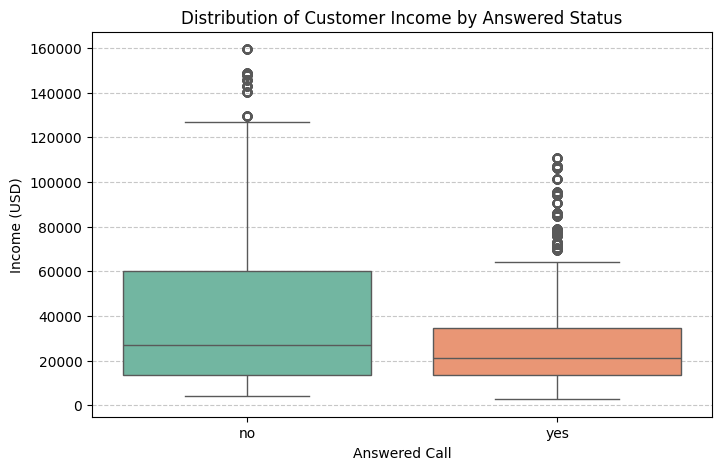

In [ ]:
# 3.1. Chart 1: Box plot of Income by Answered Status
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')
plt.title('Distribution of Customer Income by Answered Status')
plt.xlabel('Answered Call')
plt.ylabel('Income (USD)')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()

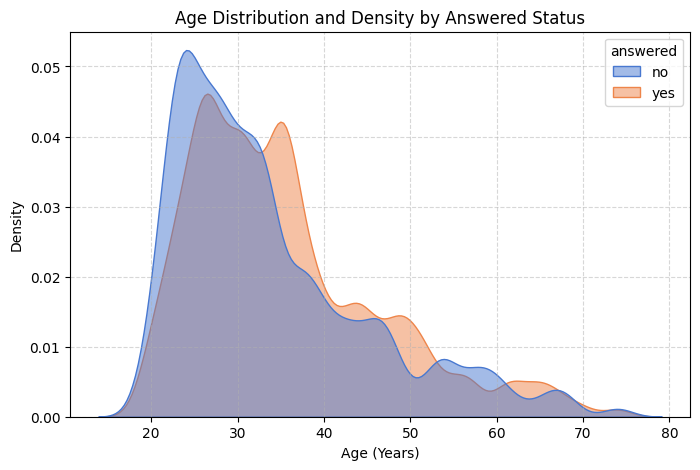

In [ ]:
# 3.2. Chart 2: Density / KDE plot of Age by Answered Status
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_clean, x='age', hue='answered', fill=True, common_norm=False, palette='muted', alpha=0.5)
plt.title('Age Distribution and Density by Answered Status')
plt.xlabel('Age (Years)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

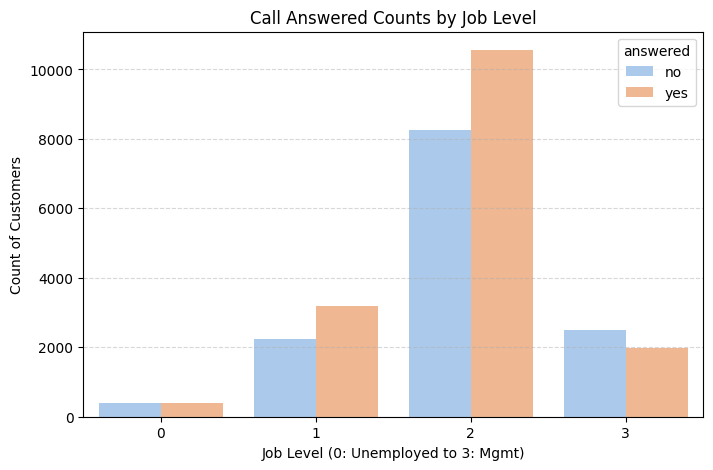

In [ ]:
# 3.3. Chart 3: Clustered Bar Chart for Job vs. Answered Status
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='job', hue='answered', palette='pastel')
plt.title('Call Answered Counts by Job Level')
plt.xlabel('Job Level (0: Unemployed to 3: Mgmt)')
plt.ylabel('Count of Customers')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()

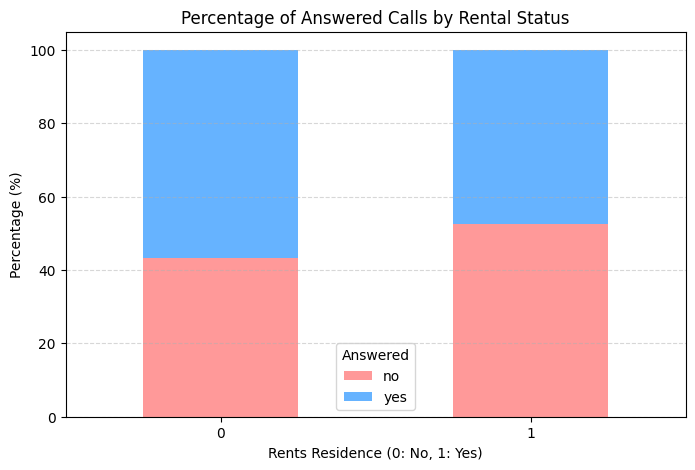

In [ ]:
# 3.4. Chart 4: Segmented Bar Chart of Rent vs. Answered Status
rent_answered = pd.crosstab(df_clean['rent'], df_clean['answered'], normalize='index') * 100

rent_answered.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#ff9999','#66b3ff'])
plt.title('Percentage of Answered Calls by Rental Status')
plt.xlabel('Rents Residence (0: No, 1: Yes)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Answered')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()

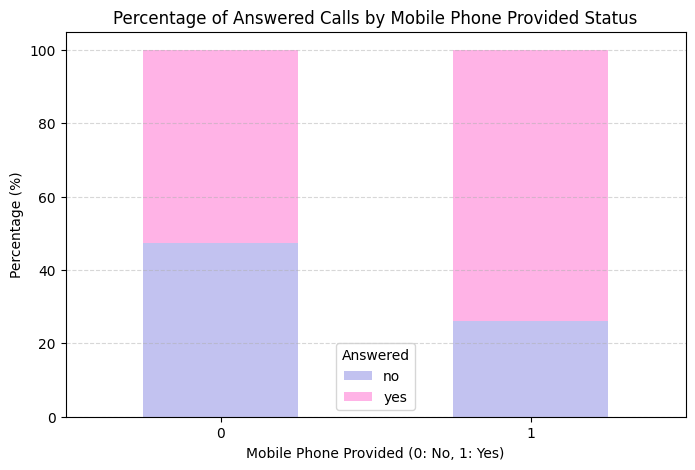

In [ ]:
# 3.5. Chart 5: Answered Rate by Mobile Phone Provided
mobile_answered = pd.crosstab(df_clean['mobile'], df_clean['answered'], normalize='index') * 100

mobile_answered.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#c2c2f0','#ffb3e6'])
plt.title('Percentage of Answered Calls by Mobile Phone Provided Status')
plt.xlabel('Mobile Phone Provided (0: No, 1: Yes)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Answered')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()

### ✍️ Please answer the following:

3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  

### ✍️ Your Response: 🔧

3.6. Mobile phone status and rental status show the strongest relationships with the target variable. Customers with a mobile phone are more likely to answer the call.

3.7.  Age and income show weaker relationships with the target variable. The distributions are similar, and there is a lot of overlap between yes and no groups.

## **Task 4. Modeling**

### **4.1. Calculate the baseline probability of answering**

If we use no model at all, how good is our chance of predicting someone answering?  
* Use a calculation to find the chances of someone answering when called.

In [ ]:
# 4.1. Get the default (baseline) probability of answering

# Count the occurrences of 'yes' and 'no' in the 'answered' column
answered_counts = df_clean['answered'].value_counts()

# Calculate the probability of answering ('yes')
baseline_prob = (df_clean['answered'] == 'yes').mean()

print("--- Answered Distribution ---")
print(answered_counts)
print(f"\nBaseline Probability of Answering: {baseline_prob * 100:.2f}%")

--- Answered Distribution ---
answered
yes    16125
no     13374
Name: count, dtype: int64

Baseline Probability of Answering: 54.66%


### **4.2. Split the training and testing datasets**

Split `df_clean` using `train_test_split()` function
- all variables except `answered` should be in the `X` variable
- `answered` is the `y` variable


In [ ]:
# 4.2 Split data into training and testing sets

# Separate features (X) and target (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split into training and testing sets (using an 80/20 split and a fixed random state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (23599, 12)
X_test shape: (5900, 12)
y_train shape: (23599,)
y_test shape: (5900,)


### **4.3. Create and Visualize a Decision Tree**
4.3.1. Use all available attributes (except those that were eliminated in step 2) to create a decision tree model
- Let us set the following parameters, `criterion` = "entropy" and  `max_depth` = 4

4.3.2. Visualize the tree

In [ ]:
# 4.3.1. Create a Decision Tree with criterion='entropy' and max_depth=4

# Initialize the Decision Tree Classifier
# Note: scikit-learn handles categorical columns natively if we encode them, but pandas category types are fine for numerical codes
# If needed, sklearn will automatically cast them, but standard practice with tree models is to pass the features directly
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Fit the model on training data
# Let's perform one-hot encoding for categorical attributes to ensure compatibility with sklearn
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

clf.fit(X_train_encoded, y_train)
print("Decision Tree Model successfully trained!")

Decision Tree Model successfully trained!


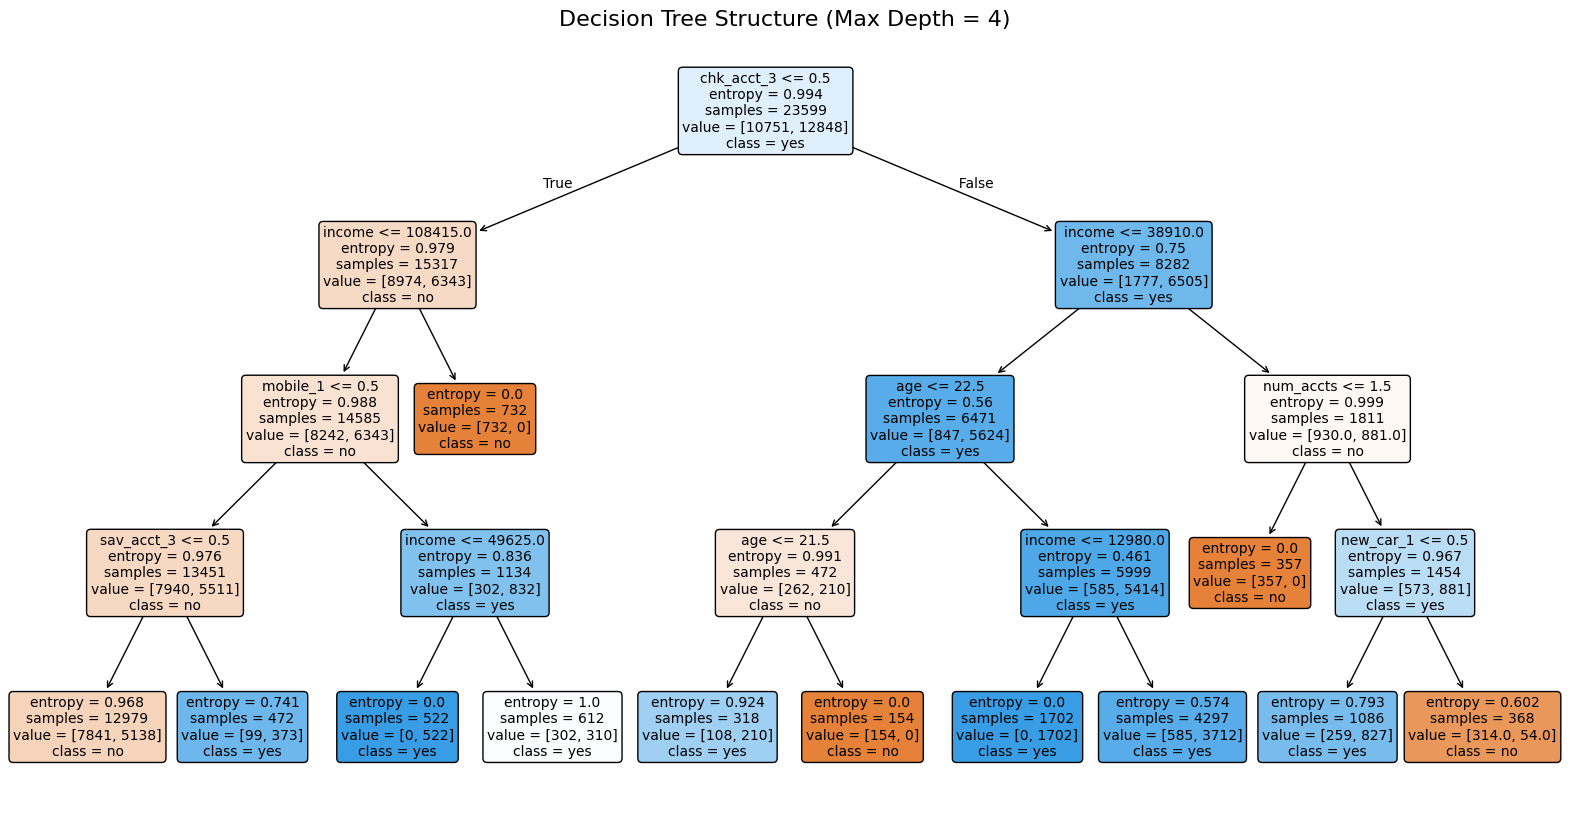

In [ ]:
# 4.3.2. display (visualize) the Tree

plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=X_train_encoded.columns.tolist(),
    class_names=clf.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4)", fontsize=16)
plt.show()

### **4.4. What is the accuracy?**

This should be better than the base probability, or you have failed in your objective

In [ ]:
# 4.4.1. Calculate the accuracy of your tree

# Predict the classes for the test dataset
y_pred = clf.predict(X_test_encoded)

# Calculate the test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline Probability of Answering: {baseline_prob * 100:.2f}%")
print(f"Decision Tree Model Test Accuracy: {test_accuracy * 100:.2f}%")

# Confirm if objective is achieved
if test_accuracy > baseline_prob:
    print(f"Success! The model improved on the baseline by {(test_accuracy - baseline_prob) * 100:.2f} percentage points.")
else:
    print("The model did not improve on the baseline.")

Baseline Probability of Answering: 54.66%
Decision Tree Model Test Accuracy: 71.00%
Success! The model improved on the baseline by 16.34 percentage points.


### ✍️ Please answer the following:

4.4.2. What is the difference between the probability from the model compared to the base probability? Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧

4.4.2. The model accuracy is 71%, while the baseline probability is 54.66%. The difference is 16.34 percentage points. This is a good improvement. It can help the business better predict which customers are likely to answer calls and make better decisions.


### **4.5: Create a confusion matrix**

This will show false positives, true positives, false negatives and true negatives.

In [ ]:
# 4.5.1 Create a basic confusion matrix using sklearn's functions

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['no', 'yes'])

# Extract details
tn, fp, fn, tp = cm.ravel()

print("--- Confusion Matrix Elements ---")
print(f"True Negatives (Predicted No, Actual No): {tn}")
print(f"False Positives (Predicted Yes, Actual No): {fp}")
print(f"False Negatives (Predicted No, Actual Yes): {fn}")
print(f"True Positives (Predicted Yes, Actual Yes): {tp}")

print("\n--- Raw Confusion Matrix ---")
print(cm)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['no', 'yes']))

--- Confusion Matrix Elements ---
True Negatives (Predicted No, Actual No): 2312
False Positives (Predicted Yes, Actual No): 311
False Negatives (Predicted No, Actual Yes): 1400
True Positives (Predicted Yes, Actual Yes): 1877

--- Raw Confusion Matrix ---
[[2312  311]
 [1400 1877]]

--- Classification Report ---
              precision    recall  f1-score   support

          no       0.62      0.88      0.73      2623
         yes       0.86      0.57      0.69      3277

    accuracy                           0.71      5900
   macro avg       0.74      0.73      0.71      5900
weighted avg       0.75      0.71      0.71      5900



Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

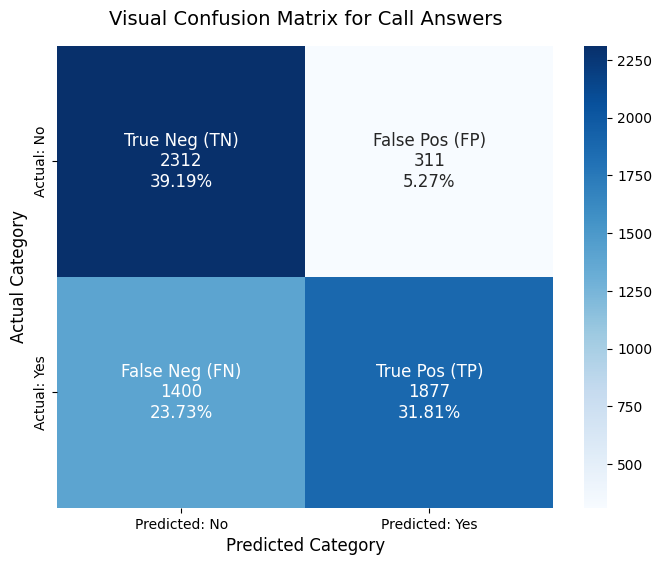

In [ ]:
# 4.5.2. Create a beautiful confusion matrix using Seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Set up labels for the heatmap cells
group_names = ['True Neg (TN)', 'False Pos (FP)', 'False Neg (FN)', 'True Pos (TP)']
group_counts = [f"{value:0.0f}" for value in cm.flatten()]
group_percentages = [f"{value:.2%}" for value in cm.flatten()/np.sum(cm)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

# Create the visual plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=labels,
    fmt='',
    cmap='Blues',
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes'],
    cbar=True,
    annot_kws={"fontsize": 12}
)

plt.title('Visual Confusion Matrix for Call Answers', fontsize=14, pad=15)
plt.ylabel('Actual Category', fontsize=12)
plt.xlabel('Predicted Category', fontsize=12)
plt.show()

## **Task 5: Evaluate the Model**

Earlier, we calculated the technical accuracy of the model. It is also important to evaluate the model economically. What would be the economic benefit of using this model for the business?

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model `answered` as the target in this case is therefore equivalent to modeling `purchased` as the target.

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- benefit: True answered * 75 -> These people purchased
- cost: False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### **5.1. Calculate the Profit Using the Model**

In [ ]:
# 5.1. Write a calculation for the profit from your model

# Assumptions
profit_per_tp = 75
cost_per_fp = 25

# Calculate expected profit from the test set predictions
model_profit = (tp * profit_per_tp) - (fp * cost_per_fp)

print("--- Economic Evaluation: Using the Model ---")
print(f"True Positives (Answered & Purchased): {tp} @ ${profit_per_tp} each = ${tp * profit_per_tp:,.2f}")
print(f"False Positives (Wasted Rep Time): {fp} @ -${cost_per_fp} each = -${fp * cost_per_fp:,.2f}")
print(f"Total Expected Profit using the model: ${model_profit:,.2f}")

--- Economic Evaluation: Using the Model ---
True Positives (Answered & Purchased): 1877 @ $75 each = $140,775.00
False Positives (Wasted Rep Time): 311 @ -$25 each = -$7,775.00
Total Expected Profit using the model: $133,000.00


### **5.2 Compare to the Default Profit**

How much profit (revenue - costs) could be expected if all customers are called? We can consider this a baseline case for profit since it does not require a model.

In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives, treat the customers who do not answer as false positives.

In [ ]:
# 5.2.1. Write a calculation for the overall profit without using the model

# Calculate counts of 'yes' and 'no' in the actual test set (y_test)
actual_yes = (y_test == 'yes').sum()
actual_no = (y_test == 'no').sum()

# Assumptions
profit_per_tp = 75
cost_per_fp = 25

# Calculate profit if all customers are called
baseline_profit = (actual_yes * profit_per_tp) - (actual_no * cost_per_fp)

print("--- Economic Evaluation: Calling All Customers (Baseline) ---")
print(f"Actual 'yes' (True Positives if all called): {actual_yes} @ ${profit_per_tp} each = ${actual_yes * profit_per_tp:,.2f}")
print(f"Actual 'no' (False Positives if all called): {actual_no} @ -${cost_per_fp} each = -${actual_no * cost_per_fp:,.2f}")
print(f"Total Baseline Profit: ${baseline_profit:,.2f}")

--- Economic Evaluation: Calling All Customers (Baseline) ---
Actual 'yes' (True Positives if all called): 3277 @ $75 each = $245,775.00
Actual 'no' (False Positives if all called): 2623 @ -$25 each = -$65,575.00
Total Baseline Profit: $180,200.00


### ✍️ Please answer the following:

5.2.2. What is the difference in profit between calling all customers and calling customers that are recommended by the model?

5.2.3. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
5.2.2. The profit from calling all customers is USD 180,200. The profit using the model is USD 133,000. The difference is USD 47,200. Calling all customers makes USD 47,200 more profit.

5.2.2 Yes, this is a significant amount for the business. The model saves some calling time, but it also misses many customers who may answer. In this case, calling all customers is more profitable.

### **5.3 Tune the Model**

5.3.1. Create a new tree by adjusting the parameters such as size or shape of the tree or others

5.3.2. then test the accuracy

Keep changing these parameters until you end up with a tree with accuracy that is **better** than the initial model

In [ ]:
# 5.3.1. Create a new version of the tree with tuned parameters
# Let's try criterion='gini' and allow a slightly deeper tree with max_depth=6 or 7, while adding regularization
tuned_clf = DecisionTreeClassifier(criterion='gini', max_depth=6, min_samples_split=20, random_state=42)
tuned_clf.fit(X_train_encoded, y_train)
print("Tuned Decision Tree Model trained successfully!")

Tuned Decision Tree Model trained successfully!


In [ ]:
# 5.3.2. Calculate evaluation metrics for the tuned tree
tuned_y_pred = tuned_clf.predict(X_test_encoded)
tuned_accuracy = accuracy_score(y_test, tuned_y_pred)

print(f"Initial Model Accuracy: {test_accuracy * 100:.2f}%")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%")

if tuned_accuracy > test_accuracy:
    print(f"Success! The tuned model improved accuracy by {(tuned_accuracy - test_accuracy) * 100:.2f} percentage points!")
else:
    print("We need to continue adjusting parameters to beat the initial model.")

Initial Model Accuracy: 71.00%
Tuned Model Accuracy: 75.97%
Success! The tuned model improved accuracy by 4.97 percentage points!


### **5.4 Apply the Model to New Customers**

5.4.1. Import the "adviseinvest_new_customer_data.csv" file

5.4.2. Perform the same data cleanup steps from Step 2 above (we have to do the same pre-processing in test data as we did in training data). Copy paste the code.

5.4.3. Using the **better** tree model you created in task 5.3, predict the target variable for each customer by feeding the new customer data into the model

5.4.4. Predict the number of customers who will answer (or not) for the target variable.

In [ ]:
# 5.4.1. Import new customer data into a new data frame
import pandas as pd
import numpy as np

# Note: Let's fetch the new customer data CSV file
# If it is available in GitHub or /content/ folder, we load it here.
try:
    df_new = pd.read_csv('/content/adviseinvest_new_customer_data.csv')
    print("New customer dataset loaded successfully!")
except FileNotFoundError:
    # Fallback to loading directly from GitHub if not found locally
    url = 'https://raw.githubusercontent.com/vandanara/UofUtah_IS4487/main/DataSets/adviseinvest_new_customer_data.csv'
    df_new = pd.read_csv(url)
    print("New customer dataset loaded successfully from GitHub!")

# 5.4.2. Perform the exact same data cleanup steps from Step 2 above

# 1. Clean outliers (using the same criteria: age <= 100, income >= 0)
df_new_clean = df_new[(df_new['age'] <= 100) & (df_new['income'] >= 0)].copy()

# 2. Cleanup missing values in 'new_car'
df_new_clean = df_new_clean.dropna(subset=['new_car']).copy()

# 3. Standardize and map the 'female' column
df_new_clean['female'] = df_new_clean['female'].astype(str).str.strip()
female_map = {'0': 0, '1': 1, '0.0': 0, '1.0': 1}
df_new_clean['female'] = df_new_clean['female'].map(female_map).fillna(0).astype(int)

# 4. Drop 'product' column if present (to avoid data leakage)
if 'product' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['product'])

# 5. Drop the target variable 'answered' if it exists in the new data
if 'answered' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['answered'])

# 6. Align variable types (integers and categoricals)
df_new_clean['new_car'] = df_new_clean['new_car'].astype(int)
df_new_clean['female'] = df_new_clean['female'].astype(int)

cat_vars = ['female', 'job', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'mobile']
for col in cat_vars:
    df_new_clean[col] = df_new_clean[col].astype('category')

print(f"Processed new dataset shape: {df_new_clean.shape}")

New customer dataset loaded successfully from GitHub!
Processed new dataset shape: (1000, 13)


In [ ]:
# 5.4.3. & 5.4.4. Apply the best model and predict

# Apply the exact same dummy encoding as applied during training
X_new_encoded = pd.get_dummies(df_new_clean, drop_first=True)

# Align columns with X_train_encoded to make sure everything matches up perfectly
# This ensures dummy columns match and are in the same order
missing_cols = set(X_train_encoded.columns) - set(X_new_encoded.columns)
for c in missing_cols:
    X_new_encoded[c] = False
X_new_encoded = X_new_encoded[X_train_encoded.columns]

# Predict using the better tuned tree model
new_predictions = tuned_clf.predict(X_new_encoded)

# Output predictions count
prediction_counts = pd.Series(new_predictions).value_counts()
print("--- Predictions on New Customer Dataset ---")
print(prediction_counts)
print(f"Predicted Answer Rate: {prediction_counts.get('yes', 0) / len(new_predictions) * 100:.2f}%")

--- Predictions on New Customer Dataset ---
no     638
yes    362
Name: count, dtype: int64
Predicted Answer Rate: 36.20%


## **Task 6: Conclusion**

### ✍️ Please answer the following:

6.1. Did we improve our profit using the model?

6.2: How else could the model be utilized by the business?


### ✍️ Your Response:

6.1.   No, we did not improve profit using the model. Calling all customers made USD 180,200, while using the model made USD 133,000. The model made USD 47,200 less profit.

6.2. The business can use the model to find customers who are more likely to answer calls. It can help the company plan calling times, save time, and focus on different customer groups. The business can also use it to improve future marketing strategies.



## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_10_Gong Linlin.ipynb"

[NbConvertApp] Converting notebook assignment_10_Gong Linlin.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1023039 bytes to assignment_10_Gong Linlin.html
